---
# **6. GEOGRAFÍA: ALTITUD Y COSTA**

**Objetivo:** añadir a cada barrio dos variables de geografía: su **altitud** y si **da al mar**.

**Entradas:**
- En **`data/raw`**: `estadisticas_terreno.csv` (estadísticas de altitud por barrio calculadas en QGIS a partir de un modelo de elevaciones LiDAR del ICGC).
- En **`data/processed`**: `barrios_base.csv` y `barrios_base.gpkg` (cuaderno 1).

**Fuente y año:** Institut Cartogràfic i Geològic de Catalunya (ICGC), Model d'Elevacions del Terreny (MET) obtenido con LiDAR, resolución de 2 m. Los datos se tomaron entre 2008 y 2011, según la zona.

**Salida** (en `data/processed`): `geografia_por_barrio.csv`, una fila por barrio con `codi_barri`, `costa` (1 si da al mar, 0 si no) y `altitud_mediana_m`.

**Limitaciones:**
- El modelo es de **2008-2011** y el resto de datos del proyecto es de 2026. El relieve cambia poco en ese tiempo, pero no es la misma fecha.
- Un solo número por barrio **esconde las diferencias dentro del barrio**: en barrios con mucho desnivel (Vallvidrera, Horta) hay zonas bajas y altas.
- La altitud influye sobre todo en la temperatura del **aire**, y nosotros usamos la del **suelo**.
- "Costa" es sí o no: no distingue un barrio que toca el mar de uno que está a 300 metros.

---

## Metodología previa: Obtención y Procesamiento de Datos

Antes de iniciar el análisis en este cuaderno de Python, se realizó una fase de preparación espacial con QGIS. Para ello se ha utilizado un modelo de elevaciones del terreno, y a partir de él se ha obtenido la altitud de cada barrio. La costa, en cambio, se marca en este cuaderno con una lista de barrios.

El análisis se ha realizado para los **73 barrios oficiales de Barcelona**, de manera que podemos comparar cómo cambian la altitud y la cercanía al mar por toda la ciudad.

## A. ¿De dónde procede la altitud?

Los datos proceden del **Institut Cartogràfic i Geològic de Catalunya (ICGC)**, el organismo cartográfico de Cataluña..

En concreto, se ha utilizado el producto **Model d'Elevacions del Terreny (MET) LiDAR de Cataluña, de 2 m**,

## B. ¿Qué es un modelo de elevaciones y qué es el LiDAR?

El **LiDAR** es un sistema que lanza pulsos de láser desde un avión y mide el tiempo que tardan en rebotar en el suelo. Con ese tiempo se calcula la altura de cada punto.

A partir de millones de puntos se construye un **modelo de elevaciones**: una imagen donde cada píxel, en lugar de un color, guarda una altura. Es un modelo del **terreno**: representa la altura del suelo, no la de los edificios o los árboles.

## C. ¿Cómo se han adaptado los datos a los 73 barrios de Barcelona?

Para poder comparar los resultados por barrios, se ha utilizado el programa **[QGIS 3.44]**.

Primero, se ha comprobado que los límites de los barrios y el modelo de elevaciones comparten un sistema de coordenadas común: **ETRS89 / UTM zona 31N (EPSG:25831)**. Esto permite que ambas capas coincidan correctamente en el espacio.

A continuación, se ha utilizado la capa de los barrios como **capa máscara** para recortar el ráster, de modo que se han eliminado las zonas que quedan fuera de Barcelona.

## D. ¿Cómo se ha obtenido la altitud de cada barrio?

El último paso ha consistido en calcular las estadísticas de cada barrio mediante la herramienta **«Estadística de zona» de QGIS**, igual que en el cuaderno 4. Esta herramienta resume todos los valores de los píxeles que se encuentran dentro de cada polígono, es decir, de cada barrio.

Se ha utilizado el prefijo `elev_` y se han calculado cinco estadísticas:

| Estadística | Columna | Qué nos indica |
|---|---|---|
| Media | `elev_mean` | La altitud promedio del barrio |
| Mediana | `elev_median` | La altitud central del barrio |
| Desviación estándar | `elev_stdev` | Cuánto varía la altitud dentro del barrio |
| Mínimo | `elev_min` | La altitud más baja |
| Máximo | `elev_max` | La altitud más alta |

Finalmente, los resultados se han exportado en formato CSV (`estadisticas_terreno.csv`), que conserva las columnas originales de la capa de barrios y añade las estadísticas.

## E. ¿Cómo se ha marcado la costa?

La costa no se calcula con un modelo, sino con una **lista de nombres** de los barrios que dan al mar.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/proyectofinal_ITAcademy/'
RAW = CARPETA + 'data/raw/'                           # Ruta limpia a la carpeta de datos originales
PROCESSED = CARPETA + 'data/processed/'              # Ruta limpia a la carpeta de procesados

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Cargamos los datos

In [3]:
base = pd.read_csv(PROCESSED + 'barrios_base.csv', encoding='utf-8-sig')
base = base[['codi_barri', 'nom_barri']]
print('Barrios:', len(base))

altitud = pd.read_csv(RAW + 'estadisticas_terreno.csv', encoding='utf-8-sig')
print('Filas y columnas:', altitud.shape)

barrios_mapa = gpd.read_file(PROCESSED + 'barrios_base.gpkg')

print('Cargado')

Barrios: 73
Filas y columnas: (73, 40)
Cargado


## 2. Inspección de los datos

### 2.1 Inspección completa de variables y estructura del DataFrame
Vamos a listar todas las columnas disponibles para entender qué datos contiene el archivo.

In [4]:
# Mostrar la lista completa de todas las columnas de la tabla
print("--- COLUMNAS EN LA TABLA ---")
print(altitud.columns.tolist())

--- COLUMNAS EN LA TABLA ---
['fid', 'ID_ANNEX', 'ANNEXDESCR', 'ID_TEMA', 'TEMA_DESCR', 'ID_CONJUNT', 'CONJ_DESCR', 'ID_SUBCONJ', 'SCONJ_DESC', 'ID_ELEMENT', 'ELEM_DESCR', 'NIVELL', 'NDESCR_CA', 'NDESCR_ES', 'NDESCR_EN', 'TERME', 'DISTRICTE', 'BARRI', 'AEB', 'SEC_CENS', 'GRANBARRI', 'ZUA', 'AREA_I', 'LITERAL', 'PERIMETRE', 'AREA', 'CODI_UA', 'TIPUS_UA', 'NOM', 'WEB1', 'WEB2', 'WEB3', 'FHEX_COLOR', 'Shape_Leng', 'Shape_Area', 'elev_mean', 'elev_median', 'elev_stdev', 'elev_min', 'elev_max']


In [5]:
# Resumen del tipo de datos e información general
print("--- INFORMACIÓN GENERAL ---")
altitud.info()

--- INFORMACIÓN GENERAL ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 40 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   fid          73 non-null     int64  
 1   ID_ANNEX     73 non-null     int64  
 2   ANNEXDESCR   73 non-null     object 
 3   ID_TEMA      73 non-null     int64  
 4   TEMA_DESCR   73 non-null     object 
 5   ID_CONJUNT   73 non-null     int64  
 6   CONJ_DESCR   73 non-null     object 
 7   ID_SUBCONJ   73 non-null     int64  
 8   SCONJ_DESC   73 non-null     object 
 9   ID_ELEMENT   73 non-null     int64  
 10  ELEM_DESCR   73 non-null     object 
 11  NIVELL       73 non-null     object 
 12  NDESCR_CA    73 non-null     object 
 13  NDESCR_ES    73 non-null     object 
 14  NDESCR_EN    73 non-null     object 
 15  TERME        73 non-null     int64  
 16  DISTRICTE    73 non-null     int64  
 17  BARRI        73 non-null     int64  
 18  AEB          73 non-null

**Qué mirar:** las primeras columnas son información administrativa del Ayuntamiento (`ID_ANNEX`, `TEMA_DESCR`...) que no nos sirve para nada. Lo importante está al final y en dos o tres columnas sueltas.

### 2.2 ¿Qué columnas aportan información?

Una columna con **un solo valor** en todas las filas no sirve para analizar. Con `nunique()` contamos cuántos valores distintos tiene cada una.

In [6]:
n_valores = altitud.nunique()
print('Columnas con un solo valor (no aportan nada):', int((n_valores == 1).sum()))
print(n_valores[n_valores == 1].index.tolist())
print()
print('Columnas con varios valores:')
print(n_valores[n_valores > 1].index.tolist())

Columnas con un solo valor (no aportan nada): 21
['ID_ANNEX', 'ANNEXDESCR', 'ID_TEMA', 'TEMA_DESCR', 'ID_CONJUNT', 'CONJ_DESCR', 'ID_SUBCONJ', 'SCONJ_DESC', 'ID_ELEMENT', 'ELEM_DESCR', 'NIVELL', 'NDESCR_CA', 'NDESCR_ES', 'NDESCR_EN', 'TERME', 'AEB', 'SEC_CENS', 'ZUA', 'AREA_I', 'TIPUS_UA', 'FHEX_COLOR']

Columnas con varios valores:
['fid', 'DISTRICTE', 'BARRI', 'GRANBARRI', 'LITERAL', 'PERIMETRE', 'AREA', 'CODI_UA', 'NOM', 'WEB1', 'WEB2', 'WEB3', 'Shape_Leng', 'Shape_Area', 'elev_mean', 'elev_median', 'elev_stdev', 'elev_min', 'elev_max']


**Qué mirar:** de las que varían, las importantes son:
- `BARRI`: el **código** del barrio (del 1 al 73).
- `NOM`: el **nombre**.
- `DISTRICTE`: el distrito.
- `AREA`: la superficie del barrio en m².
- Las **estadísticas** que añadió QGIS, con prefijo `elev_`: `mean` (media), `median` (mediana), `stdev` (desviación), `min` y `max`.

Las demás (enlaces web, colores, códigos del Ayuntamiento) las descartamos.

### 2.3 Valores vacíos y duplicados

In [7]:
print('vacíos:', altitud.isna().sum().sum(), '| códigos de barrio repetidos:', altitud['BARRI'].duplicated().sum())

vacíos: 0 | códigos de barrio repetidos: 0


## 3. Limpieza

### 3.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros

In [8]:
alt = altitud[['BARRI', 'NOM', 'elev_mean', 'elev_median', 'elev_stdev', 'elev_min', 'elev_max']].copy()
alt = alt.rename(columns={
    'BARRI': 'codi_barri', 'NOM': 'nom_barri',
    'elev_mean': 'altitud_media', 'elev_median': 'altitud_mediana',
    'elev_stdev': 'altitud_desv', 'elev_min': 'altitud_min', 'elev_max': 'altitud_max'})
display(alt.head(3).round(2))


,codi_barri,nom_barri,altitud_media,altitud_mediana,altitud_desv,altitud_min,altitud_max
0,1,el Raval,8.86,8.25,4.06,-1.70,20.78
1,2,el Barri Gòtic,7.57,6.85,3.78,-2.22,16.84
2,3,la Barceloneta,3.80,4.14,2.19,-10.54,12.13


La **mediana** (`elev_median`) será nuestra medida principal, porque no le afectan los píxeles extremos de un barrio con mucho desnivel.

In [9]:
print('Altitud mediana de los barrios (m): mínimo', round(alt['altitud_mediana'].min(), 2),
      '| mediana', round(alt['altitud_mediana'].median(), 2), '| máximo', round(alt['altitud_mediana'].max(), 2))

Altitud mediana de los barrios (m): mínimo 3.37 | mediana 51.41 | máximo 319.67


## 4. Mapa de Altitud Mediana por Barrio
Vamos a generar un mapa donde la intensidad del color muestre la altitud de cada uno de los 73 barrios de Barcelona.

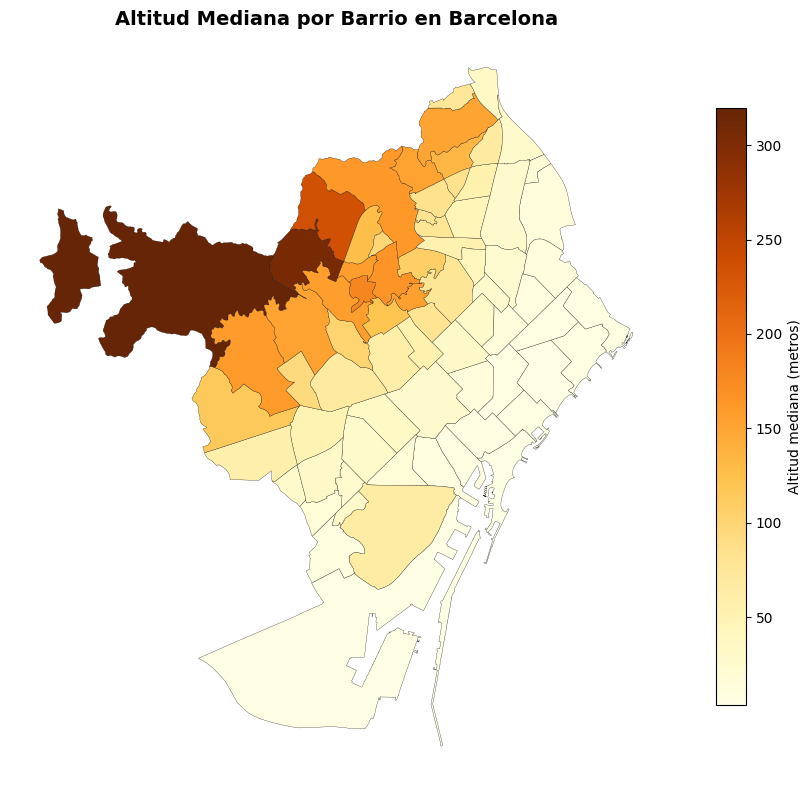

In [10]:
# 1. Unimos los datos espaciales con 'alt' (que ya tiene 'altitud_mediana' limpia)
mapa_altitud = barrios_mapa[['codi_barri', 'geometry']].merge(alt, on='codi_barri')

# 2. Creamos el mapa visualizando la columna 'altitud_mediana'
fig, eje = plt.subplots(figsize=(11, 8))
grafico = mapa_altitud.plot(
    column='altitud_mediana',
    cmap='YlOrBr',
    edgecolor='black',
    linewidth=0.2,
    legend=True,
    legend_kwds={'label': "Altitud mediana (metros)", 'orientation': "vertical", 'shrink': 0.8},
    ax=eje
)

# Añadimos título y quitamos los ejes coordenados
eje.set_title('Altitud Mediana por Barrio en Barcelona', fontweight='bold', fontsize=14)
eje.axis('off')

plt.tight_layout()
plt.show()

**Qué mirar:** el color indica la altura: cuanto más oscuro (marrón), más alto está el barrio, y cuanto más claro (amarillo), más cerca está del mar.
- **La sierra de Collserola (noroeste):** la zona más oscura es la más alta de Barcelona, con Vallvidrera, el Tibidabo i les Planes y Sant Genís dels Agudells.
- **Las laderas del norte:** los tonos naranjas (entre unos 100 y 250 m) son barrios en pendiente, como Montbau, el Coll, el Carmel o Torre Baró.
- **La llanura junto al mar (este y sur):** casi toda la ciudad está en amarillo muy claro, a poca altura (menos de unos 35 m). Aquí están el Eixample y la costa.
- **La excepción del Poble-sec:** destaca como una mancha naranja clara en el sur, junto al puerto, porque incluye la montaña de Montjuïc, que es un relieve aislado cerca del mar.


## 3. Marcamos los barrios de costa
Seleccionamos los barrios que dan al mar.

In [11]:
BARRIOS_COSTA = [
    'la Barceloneta',
    'la Vila Olímpica del Poblenou',
    'el Poblenou',
    'Diagonal Mar i el Front Marítim del Poblenou',
    'el Besòs i el Maresme',
    'el Barri Gòtic',
    'el Raval',
    'la Marina del Prat Vermell'
]

base['costa'] = base['nom_barri'].isin(BARRIOS_COSTA).astype(int)
print('Barrios marcados como costa:', int(base['costa'].sum()))

Barrios marcados como costa: 8


### 3.1 Comprobamos en el mapa
Dibujamos los barrios de costa en rojo y los demás en gris, con su nombre.

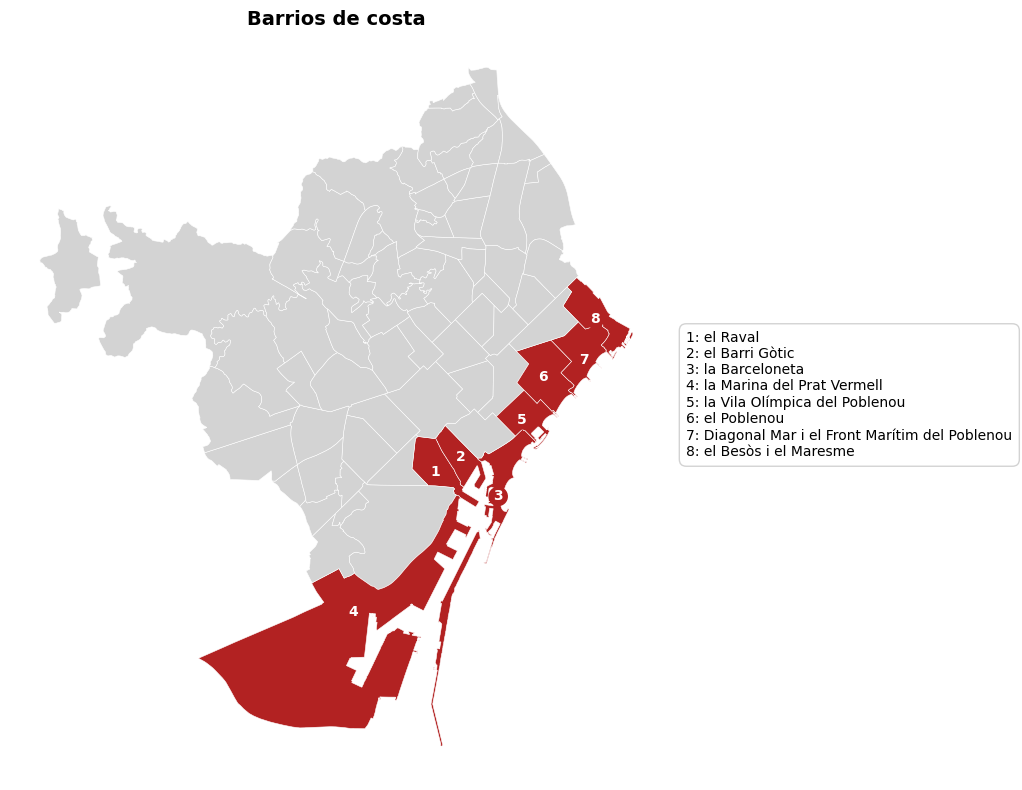

In [12]:
# 1. Unimos los datos espaciales con 'base' (que ya tiene 'costa' agregada)
mapa = barrios_mapa[['codi_barri', 'geometry']].merge(base, on='codi_barri')

fig, eje = plt.subplots(figsize=(10, 8))

# 2. Dibujamos el mapa base
mapa.plot(color=np.where(mapa['costa'] == 1, 'firebrick', 'lightgrey'), edgecolor='white', linewidth=0.4, ax=eje)

# Filtramos solo los barrios de costa
barrios_costa = mapa[mapa['costa'] == 1].copy().reset_index(drop=True)

# Añadimos un número de índice a cada barrio de costa en el mapa y creamos la leyenda
lineas_leyenda = []
for i, fila in barrios_costa.iterrows():
    indice = i + 1
    punto = fila['geometry'].representative_point()

    # Dibujamos el número en el mapa
    eje.text(punto.x, punto.y, str(indice), fontsize=10, color='white',
             weight='bold', ha='center', va='center',
             bbox=dict(boxstyle='circle,pad=0.2', fc='firebrick', ec='none'))

    # Guardamos para la lista de la leyenda
    lineas_leyenda.append(f"{indice}: {fila['nom_barri']}")

eje.set_title('Barrios de costa', fontweight='bold', fontsize=14)
eje.axis('off')

# Mostramos la leyenda de números al lado derecho del mapa
texto_leyenda = "\n".join(lineas_leyenda)
plt.figtext(0.85, 0.5, texto_leyenda, fontsize=10, va='center',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='lightgray'))

plt.tight_layout()
plt.show()

## 4. Unimos y guardamos
Juntamos costa y altitud en una sola tabla, con una fila por barrio.

In [13]:
geografia = base[['codi_barri', 'costa']].merge(alt, on='codi_barri', how='left', validate='one_to_one')
geografia['altitud_mediana'] = geografia['altitud_mediana'].round(1)

geografia.to_csv(PROCESSED + 'geografia_por_barrio.csv', index=False, encoding='utf-8-sig')

print('Guardado geografia_por_barrio.csv:', geografia.shape)
display(geografia.head(3))

Guardado geografia_por_barrio.csv: (73, 8)


,codi_barri,costa,nom_barri,altitud_media,altitud_mediana,altitud_desv,altitud_min,altitud_max
0,1,1,el Raval,8.862981,8.2,4.061734,-1.70,20.780001
1,2,1,el Barri Gòtic,7.569915,6.8,3.775241,-2.22,16.840000
2,3,1,la Barceloneta,3.798976,4.1,2.190028,-10.54,12.130000
